In [21]:
# impoorting necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.patches as patches

In [36]:
# making prep for loading data
FILE_PATH = '/content/clustering_data.csv'
HOME_STATE = "ANDHRA PRADESH"
K = 6
MAX_ITERATIONS = 100
CLUSTER_CMAP = 'tab10'
BORDER_POINT_THRESHOLD = 1.5 # (Dist to 2nd nearest) / (Dist to nearest). Lower = more border points

In [37]:
# Loading the data
print(f"Loading the data ....")
try:
    df_all = pd.read_csv(FILE_PATH, encoding='utf-8', low_memory=False)
    print(f"Data was loaded and Columns are : {df_all.columns.tolist()}")
except Exception as e:
    print(f"Error loading data: {e}")
    exit()


Loading the data ....
Data was loaded and Columns are : ['CircleName', 'RegionName', 'DivisionName', 'OfficeName', 'Pincode', 'OfficeType', 'Delivery', 'District', 'StateName', 'Latitude', 'Longitude']


In [38]:
# Data filtering
print(f"\nFiltering data for the required home state: '{HOME_STATE}'")
state_column = 'StateName'
longitude_col_raw = 'Longitude'
latitude_col_raw = 'Latitude'
# checking basic columns
required_cols = [state_column, longitude_col_raw, latitude_col_raw]
if not all(col in df_all.columns for col in required_cols):
    print("Some columns were missing, Please check again")
    exit()

df_state = df_all[df_all[state_column] == HOME_STATE].copy()
if df_state.empty:
    print(f"No data found for state '{HOME_STATE}'.")
    exit()
print(f"Found {len(df_state)} initial entries for {HOME_STATE}.")


Filtering data for the required home state: 'ANDHRA PRADESH'
Found 10634 initial entries for ANDHRA PRADESH.


In [39]:
df_all.head(1)

,CircleName,RegionName,DivisionName,OfficeName,Pincode,OfficeType,Delivery,District,StateName,Latitude,Longitude
0,Andhra Pradesh Circle,Kurnool Region,Hindupur Division,Peddakotla B.O,515631,BO,Delivery,ANANTAPUR,ANDHRA PRADESH,14.5689,77.85624


In [40]:
df_state.head(1)

,CircleName,RegionName,DivisionName,OfficeName,Pincode,OfficeType,Delivery,District,StateName,Latitude,Longitude
0,Andhra Pradesh Circle,Kurnool Region,Hindupur Division,Peddakotla B.O,515631,BO,Delivery,ANANTAPUR,ANDHRA PRADESH,14.5689,77.85624


In [41]:
# Data Preprocessing
longitude_col = 'lon'
latitude_col = 'lat'
df_state = df_state[[longitude_col_raw, latitude_col_raw]].copy()
df_state.rename(columns={longitude_col_raw: longitude_col, latitude_col_raw: latitude_col}, inplace=True)

# Converting to numeric & handling errors
df_state[longitude_col] = pd.to_numeric(df_state[longitude_col], errors='coerce')
df_state[latitude_col] = pd.to_numeric(df_state[latitude_col], errors='coerce')
initial_rows = len(df_state)
df_state.dropna(subset=[longitude_col, latitude_col], inplace=True)
print(f"Removing {initial_rows - len(df_state)} rows due to missing/non-numeric coordinates.")

# filtering Outlier (we should adjust ranges for the required state)
lat_min_bound, lat_max_bound = 12.5, 20.0
lon_min_bound, lon_max_bound = 76.5, 85.0
initial_rows = len(df_state)
df_state = df_state[
    (df_state[latitude_col] >= lat_min_bound) & (df_state[latitude_col] <= lat_max_bound) &
    (df_state[longitude_col] >= lon_min_bound) & (df_state[longitude_col] <= lon_max_bound)
]
print(f"Removeing {initial_rows - len(df_state)} rows outside plausible coordinate range.")

if df_state.empty:
    print("No valid data remaining after cleaning.")
    exit()
print(f"Final dataset size for clustering: {len(df_state)} pincodes.")

# Preparing data matrix X
X = df_state[[longitude_col, latitude_col]].values
print(f"The prepared data matrix X with shape: {X.shape}")

Removing 1039 rows due to missing/non-numeric coordinates.
Removeing 483 rows outside plausible coordinate range.
Final dataset size for clustering: 9112 pincodes.
The prepared data matrix X with shape: (9112, 2)


In [42]:
# making K-means from sctrach
def euclidean_distance(p1, p2):
    return np.sqrt(np.sum((np.asarray(p1) - np.asarray(p2))**2))
def kmeans_from_scratch(X, k, max_iterations):
    n_samples, n_features = X.shape
    if not (0 < k <= n_samples):
        print(f"Invalid K={k}. Must be 0 < K <= {n_samples}.")
        return None, None, None

    # initialization
    indices = np.random.choice(n_samples, k, replace=False)
    centroids = X[indices].astype(float)
    print(f"initially K={k} centroids were chosen.")

    labels = np.zeros(n_samples, dtype=int)
    all_distances = np.zeros((n_samples, k)) # for storing distances to all centroids

    for i in range(max_iterations):
        # assigining step and distance calculation
        for point_idx, point in enumerate(X):
            distances_to_centroids = [euclidean_distance(point, c) for c in centroids]
            all_distances[point_idx, :] = distances_to_centroids
            labels[point_idx] = np.argmin(distances_to_centroids)

        # updating step
        new_centroids = np.array([X[labels == j].mean(axis=0) if (labels == j).any() else centroids[j]  for j in range(k)])

        # Checking for empty cluster re-initialization
        for j in range(k):
            if not (labels == j).any():
                 print(f"Cluster {j} empty at iter {i+1}. so, re-initializing centroid randomly.")
                 new_centroids[j] = X[np.random.choice(n_samples)].astype(float)


        # Convergence checking
        if np.allclose(centroids, new_centroids, atol=1e-4, rtol=1e-4):
            print(f"K-Means is converged after {i+1} iterations.")
            centroids = new_centroids
            for point_idx, point in enumerate(X):
                 distances_to_centroids = [euclidean_distance(point, c) for c in centroids]
                 all_distances[point_idx, :] = distances_to_centroids
                 labels[point_idx] = np.argmin(distances_to_centroids)
            return centroids, labels, all_distances

        centroids = new_centroids

    print(f"K-Means has reached max iterations ({max_iterations}).")
    for point_idx, point in enumerate(X):
        distances_to_centroids = [euclidean_distance(point, c) for c in centroids]
        all_distances[point_idx, :] = distances_to_centroids
        labels[point_idx] = np.argmin(distances_to_centroids)
    return centroids, labels, all_distances


In [43]:
# applying K-Means
print(f"applying K-Means with K={K}...")
final_centroids, cluster_labels, all_distances_to_centroids = kmeans_from_scratch(X, K, MAX_ITERATIONS)

if final_centroids is None:
    print("The Clustering has been failed.tru again")
    exit()

df_state['Cluster'] = cluster_labels
# Calculating distance to assigned centroid for each point
dist_to_assigned_centroid = np.array([all_distances_to_centroids[i, label] for i, label in enumerate(cluster_labels)])
df_state['DistToCentroid'] = dist_to_assigned_centroid

# identifying border points
border_points_mask = np.zeros(len(df_state), dtype=bool)
if K > 1: # because we need atleat 2 clusters
    # sorting the distances for each point
    sorted_distances = np.sort(all_distances_to_centroids, axis=1)
    dist_nearest = sorted_distances[:, 0]
    dist_second_nearest = sorted_distances[:, 1]
    ratio = np.divide(dist_second_nearest, dist_nearest,
                      out=np.full_like(dist_nearest, np.inf),
                      where=dist_nearest != 0)
    border_points_mask = (ratio < BORDER_POINT_THRESHOLD)
    df_state['IsBorder'] = border_points_mask
    print(f"successfully identified {np.sum(border_points_mask)} potential border points (ratio < {BORDER_POINT_THRESHOLD}).")
else:
    df_state['IsBorder'] = False
    print("Skipping border point identification as k =1.")

applying K-Means with K=6...
initially K=6 centroids were chosen.
K-Means is converged after 23 iterations.
successfully identified 2020 potential border points (ratio < 1.5).


<ipython-input-44-56a862bf39f1>:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap(CLUSTER_CMAP, K)


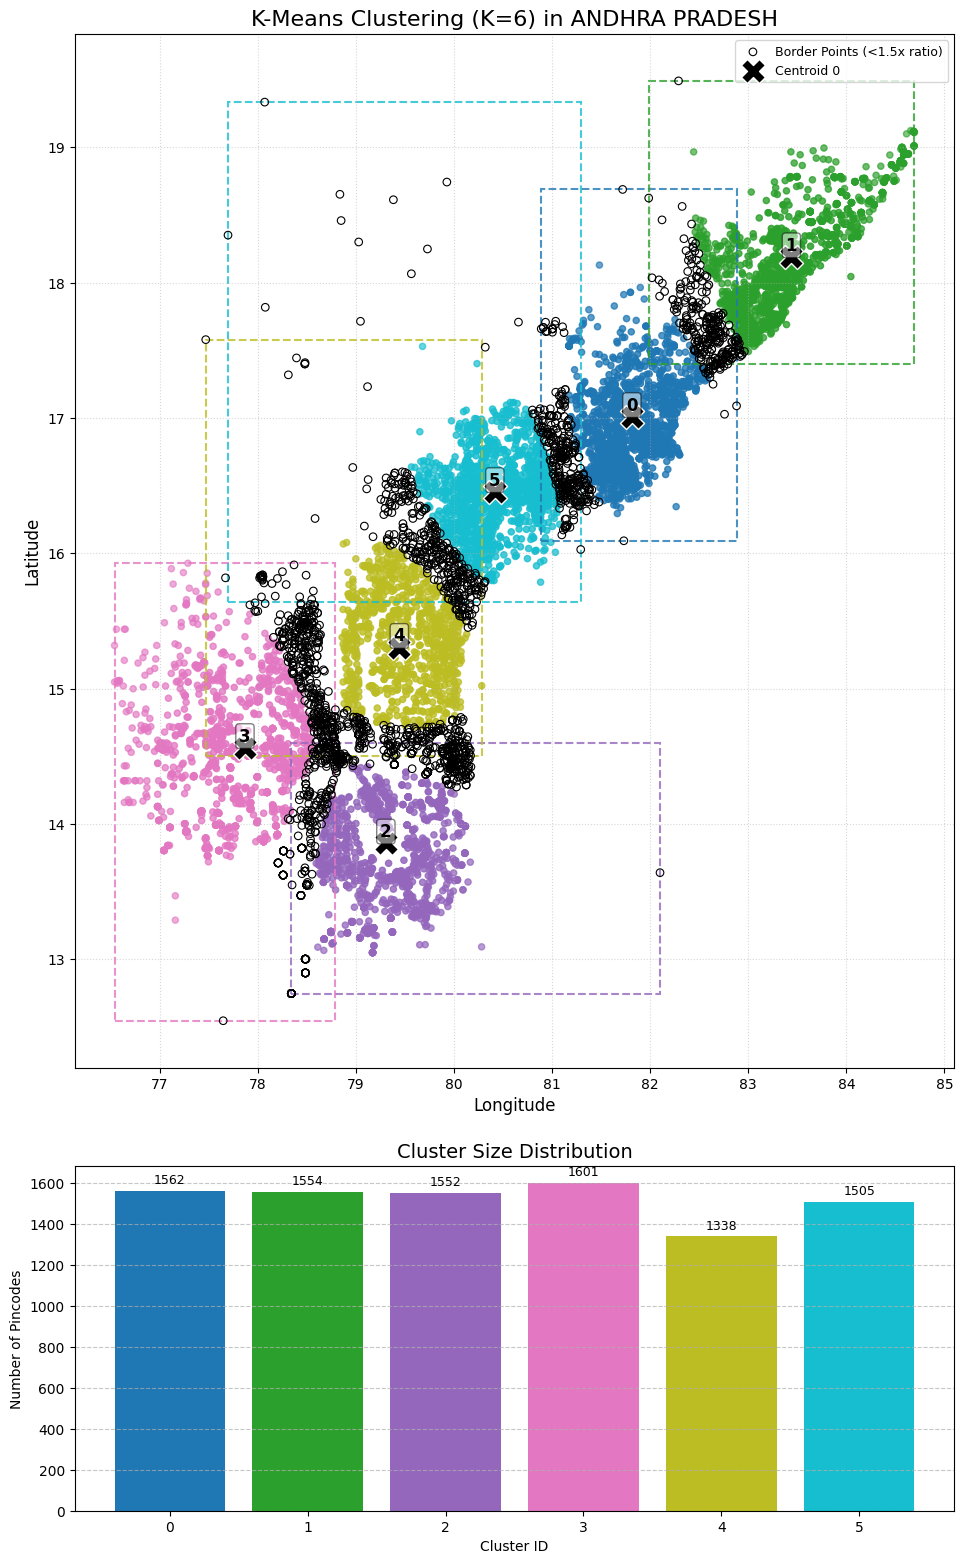

In [44]:
# visualizations

fig = plt.figure(figsize=(10, 16))
gs = fig.add_gridspec(2, 1, height_ratios=(3, 1))

# plot1 -> main cluster map
ax_map = fig.add_subplot(gs[0, 0])
cmap = cm.get_cmap(CLUSTER_CMAP, K)

# normalizing distances within each cluster for better alpha scaling
max_dist = df_state['DistToCentroid'].max()
min_alpha, max_alpha = 0.15, 0.9
point_alphas = max_alpha - (df_state['DistToCentroid'] / max_dist) * (max_alpha - min_alpha)
point_alphas = np.clip(point_alphas, min_alpha, max_alpha)

# plotting non-border points
non_border_mask = ~df_state['IsBorder']
for i in range(K):
    cluster_mask = (df_state['Cluster'] == i) & non_border_mask
    if cluster_mask.any():
        cluster_points = df_state.loc[cluster_mask, [longitude_col, latitude_col]].values
        cluster_alphas = point_alphas[cluster_mask]
        ax_map.scatter(cluster_points[:, 0], cluster_points[:, 1], s=20,
                       color=cmap(i), label=f'Cluster {i}' if not df_state['IsBorder'].any() else None,
                       alpha=cluster_alphas)

# plotting border points distinctly
border_points_data = df_state[df_state['IsBorder']]
if not border_points_data.empty:
     ax_map.scatter(border_points_data[longitude_col], border_points_data[latitude_col],
                    s=30,
                    facecolors='none',
                    edgecolors='black',
                    linewidth=0.8,
                    label=f'Border Points (<{BORDER_POINT_THRESHOLD}x ratio)',
                    zorder=5) # plotting below centroids but above regular points

# plotting centroids and add bounding boxes
for i in range(K):
    cluster_subset = df_state[df_state['Cluster'] == i]
    if not cluster_subset.empty:
        centroid = final_centroids[i]
        ax_map.scatter(centroid[0], centroid[1], marker='X', s=300, c='black', edgecolor='white', linewidth=1, label=f'Centroid {i}' if i == 0 else None, zorder=10)
        ax_map.text(centroid[0], centroid[1] + 0.02, f'{i}', fontsize=12, fontweight='bold', color='black', ha='center', va='bottom', zorder=11, bbox=dict(facecolor='white', alpha=0.5, boxstyle='round,pad=0.2'))

        lon_min, lon_max = cluster_subset[longitude_col].min(), cluster_subset[longitude_col].max()
        lat_min, lat_max = cluster_subset[latitude_col].min(), cluster_subset[latitude_col].max()
        rect = patches.Rectangle((lon_min, lat_min), lon_max - lon_min, lat_max - lat_min,
                                 linewidth=1.5, edgecolor=cmap(i), facecolor='none', linestyle='--', alpha=0.8)
        ax_map.add_patch(rect)

ax_map.set_title(f'K-Means Clustering (K={K}) in {HOME_STATE}', fontsize=16)
ax_map.set_xlabel('Longitude', fontsize=12)
ax_map.set_ylabel('Latitude', fontsize=12)
ax_map.grid(True, linestyle=':', alpha=0.5)
ax_map.legend(loc='upper right', fontsize=9)


# Bar Chart - cluster size
ax_bar = fig.add_subplot(gs[1, 0])
cluster_counts = df_state['Cluster'].value_counts().sort_index()
bars = ax_bar.bar(cluster_counts.index, cluster_counts.values, color=[cmap(i) for i in cluster_counts.index])
ax_bar.set_title('Cluster Size Distribution', fontsize=14)
ax_bar.set_xlabel('Cluster ID', fontsize=10)
ax_bar.set_ylabel('Number of Pincodes', fontsize=10)
ax_bar.set_xticks(cluster_counts.index)
ax_bar.bar_label(bars, padding=3, fontsize=9)
ax_bar.grid(axis='y', linestyle='--', alpha=0.7)


plt.tight_layout(pad=2.0)
plt.show()

In [47]:
# some info from above
cluster_profiles = {}
for i in range(K):
    profile = {}
    cluster_subset = df_state[df_state['Cluster'] == i]
    count = len(cluster_subset)
    profile['ID'] = i
    profile['Size'] = count

    if count > 0:
        centroid = final_centroids[i]
        profile['Centroid'] = (f"{centroid[0]:.4f}", f"{centroid[1]:.4f}")
        distances = cluster_subset['DistToCentroid']
        profile['AvgDist'] = distances.mean()
        profile['StdDist'] = distances.std()
        lon_min, lon_max = cluster_subset[longitude_col].min(), cluster_subset[longitude_col].max()
        lat_min, lat_max = cluster_subset[latitude_col].min(), cluster_subset[latitude_col].max()
        profile['LonRange'] = (f"{lon_min:.3f}", f"{lon_max:.3f}")
        profile['LatRange'] = (f"{lat_min:.3f}", f"{lat_max:.3f}")
        profile['BBoxArea'] = (lon_max - lon_min) * (lat_max - lat_min)
        profile['Density'] = count / profile['BBoxArea'] if profile['BBoxArea'] > 0 else np.inf
        height = lat_max - lat_min
        width = lon_max - lon_min
        profile['AspectRatio'] = width / height if height > 0 else np.inf
        profile['BorderPoints'] = cluster_subset['IsBorder'].sum()

        # finding nearest other centroid
        if K > 1:
            other_centroids = np.delete(final_centroids, i, axis=0)
            distances_to_others = [euclidean_distance(centroid, other_c) for other_c in other_centroids]
            min_dist_idx = np.argmin(distances_to_others)
            original_indices = np.delete(np.arange(K), i)
            profile['NearestNeighborCentroidID'] = original_indices[min_dist_idx]
            profile['DistToNearestNeighbor'] = distances_to_others[min_dist_idx]
        else:
             profile['NearestNeighborCentroidID'] = 'N/A'
             profile['DistToNearestNeighbor'] = 'N/A'

    else:
      continue

    cluster_profiles[i] = profile

In [49]:
# printing the info
for i in range(K):
    p = cluster_profiles[i]
    if p['Size'] == 0:
        print(f"\nCluster {i} (EMPTY)")
        continue

    print(f"\nCluster {i}:")
    print(f"  - Size: {p['Size']} pincodes ({p['BorderPoints']} border points)")
    print(f"  - Core Location (Centroid): Lon={p['Centroid'][0]}, Lat={p['Centroid'][1]}")
    print(f"  - Spatial Extent (Bounding Box):")
    print(f"      Lon: {p['LonRange'][0]} to {p['LonRange'][1]}")
    print(f"      Lat: {p['LatRange'][0]} to {p['LatRange'][1]}")
    aspect_desc = "roughly square"
    if p['AspectRatio'] > 1.5: aspect_desc = "wider (East-West)"
    elif p['AspectRatio'] < 0.67: aspect_desc = "taller (North-South)"
    print(f"  - Shape (Approx.): Aspect Ratio = {p['AspectRatio']:.2f} ({aspect_desc})")
    print(f"  - Compactness: Avg Dist = {p['AvgDist']:.4f} (StdDev: {p['StdDist']:.4f})")
    print(f"  - Relative Density: {p['Density']:.2f} points/unit area (higher = denser)")
    if K > 1:
        print(f"  - Closest Neighbor: Cluster {p['NearestNeighborCentroidID']} (Distance: {p['DistToNearestNeighbor']:.4f})")


Cluster 0:
  - Size: 1562 pincodes (263 border points)
  - Core Location (Centroid): Lon=81.8139, Lat=17.0096
  - Spatial Extent (Bounding Box):
      Lon: 80.890 to 82.881
      Lat: 16.094 to 18.690
  - Shape (Approx.): Aspect Ratio = 0.77 (roughly square)
  - Compactness: Avg Dist = 0.4838 (StdDev: 0.2418)
  - Relative Density: 302.17 points/unit area (higher = denser)
  - Closest Neighbor: Cluster 5 (Distance: 1.5030)

Cluster 1:
  - Size: 1554 pincodes (138 border points)
  - Core Location (Centroid): Lon=83.4398, Lat=18.1903
  - Spatial Extent (Bounding Box):
      Lon: 81.985 to 84.695
      Lat: 17.399 to 19.492
  - Shape (Approx.): Aspect Ratio = 1.29 (roughly square)
  - Compactness: Avg Dist = 0.5971 (StdDev: 0.3263)
  - Relative Density: 274.10 points/unit area (higher = denser)
  - Closest Neighbor: Cluster 0 (Distance: 2.0094)

Cluster 2:
  - Size: 1552 pincodes (449 border points)
  - Core Location (Centroid): Lon=79.3061, Lat=13.8581
  - Spatial Extent (Bounding Box):
